In [1]:
print("Name:Waheed Ullah")
print("Roll No:23p-3079")

Name:Waheed Ullah
Roll No:23p-3079


**TASK 1 — Keras Model**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report


In [5]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping

In [6]:
df = pd.read_csv('Churn_Modelling.csv')

In [7]:
X = df.iloc[:, 3:13].values
y = df.iloc[:, 13].values

In [8]:
le = LabelEncoder()
X[:, 2] = le.fit_transform(X[:, 2])

In [9]:
ct = ColumnTransformer(transformers=[('encoder', OneHotEncoder(), [1])], remainder='passthrough')
X = np.array(ct.fit_transform(X))

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [12]:
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

**Step 2: Build ANN Model**

In [13]:
model = Sequential()

model.add(Dense(units=6, activation='relu', input_dim=12))
model.add(Dense(units=6, activation='relu'))
model.add(Dense(units=1, activation='sigmoid'))

model.summary()

C:\Users\STUDENT\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 6)                   │              78 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 6)                   │              42 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │               7 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 127 (508.00 B)

 Trainable params: 127 (508.00 B)

 Non-trainable params: 0 (0.00 B)

**Step 3: Compile Model**

In [14]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

**Step 4: Train Model**

In [15]:
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    batch_size=32,
    epochs=100,
    validation_split=0.1,
    callbacks=[early_stop]
)

Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.5528 - loss: 0.6904 - val_accuracy: 0.5750 - val_loss: 0.6796
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5708 - loss: 0.6841 - val_accuracy: 0.5875 - val_loss: 0.6733
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5917 - loss: 0.6788 - val_accuracy: 0.6000 - val_loss: 0.6684
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5986 - loss: 0.6747 - val_accuracy: 0.6250 - val_loss: 0.6644
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5931 - loss: 0.6708 - val_accuracy: 0.6500 - val_loss: 0.6591
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5875 - loss: 0.6674 - val_accuracy: 0.6500 - val_loss: 0.6538
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5917 - loss: 0.6640 - val_accuracy: 0.6500 - val_loss: 0.6496
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5972 - loss: 0.6608 - val_accuracy: 0.6500 -

**Step 5: Evaluate Model**

In [17]:
y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Report:\n", classification_report(y_test, y_pred))

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
Accuracy: 0.585
Confusion Matrix:
 [[62 39]
 [44 55]]
Report:
               precision    recall  f1-score   support

           0       0.58      0.61      0.60       101
           1       0.59      0.56      0.57        99

    accuracy                           0.58       200
   macro avg       0.59      0.58      0.58       200
weighted avg       0.59      0.58      0.58       200



**Step 6: Plot Training Graphs**

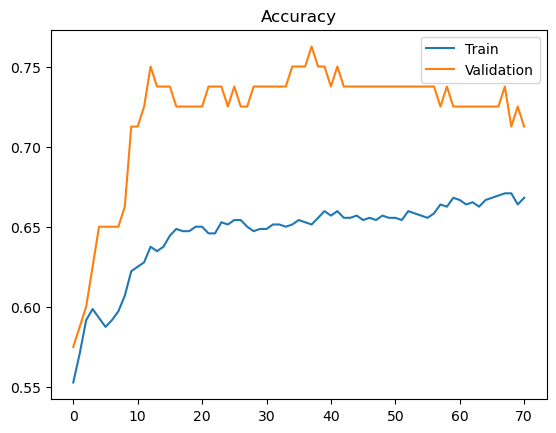

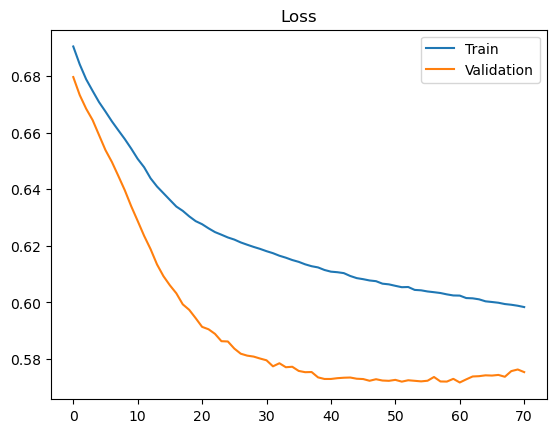

In [18]:
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title("Accuracy")
plt.legend()
plt.show()

plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title("Loss")
plt.legend()
plt.show()

**Step 7: Experiment**


Version 1 — 4 Neurons

In [20]:
model = Sequential()

model.add(Dense(units=4, activation='relu', input_dim=12))
model.add(Dense(units=4, activation='relu'))
model.add(Dense(units=1, activation='sigmoid'))

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train, epochs=100, batch_size=32, validation_split=0.1)

y_pred = (model.predict(X_test) > 0.5).astype(int)
print("Accuracy (4 neurons):", accuracy_score(y_test, y_pred))

Epoch 1/100


C:\Users\STUDENT\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.4722 - loss: 0.7013 - val_accuracy: 0.5875 - val_loss: 0.6893
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4917 - loss: 0.6989 - val_accuracy: 0.5500 - val_loss: 0.6881
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4972 - loss: 0.6970 - val_accuracy: 0.5375 - val_loss: 0.6877
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5000 - loss: 0.6954 - val_accuracy: 0.5375 - val_loss: 0.6870
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5139 - loss: 0.6942 - val_accuracy: 0.5500 - val_loss: 0.6866
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5153 - loss: 0.6931 - val_accuracy: 0.5500 - val_loss: 0.6864
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5194 - loss: 0.6923 - val_accuracy: 0.5500 - val_loss: 0.6861
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5250 - loss: 0.6915 - val_accuracy: 0.5500 - val_loss: 0

**Version 2 — 8 Neurons**

In [21]:
model = Sequential()

model.add(Dense(units=8, activation='relu', input_dim=12))
model.add(Dense(units=8, activation='relu'))
model.add(Dense(units=1, activation='sigmoid'))

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train, epochs=100, batch_size=32, validation_split=0.1)

y_pred = (model.predict(X_test) > 0.5).astype(int)
print("Accuracy (8 neurons):", accuracy_score(y_test, y_pred))

C:\Users\STUDENT\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.4917 - loss: 0.7153 - val_accuracy: 0.5375 - val_loss: 0.7066
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5097 - loss: 0.7047 - val_accuracy: 0.5125 - val_loss: 0.7001
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5403 - loss: 0.6966 - val_accuracy: 0.5375 - val_loss: 0.6957
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5625 - loss: 0.6917 - val_accuracy: 0.5750 - val_loss: 0.6921
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5708 - loss: 0.6878 - val_accuracy: 0.5625 - val_loss: 0.6879
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5833 - loss: 0.6842 - val_accuracy: 0.5750 - val_loss: 0.6830
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6000 - loss: 0.6807 - val_accuracy: 0.6375 - val_loss: 0.6796
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6111 - loss: 0.6773 - val_accuracy: 0.6500 

**Version 3 — 16 Neurons**

In [23]:
model = Sequential()

model.add(Dense(units=16, activation='relu', input_dim=12))
model.add(Dense(units=16, activation='relu'))
model.add(Dense(units=1, activation='sigmoid'))

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train, epochs=100, batch_size=32, validation_split=0.1)

y_pred = (model.predict(X_test) > 0.5).astype(int)
print("Accuracy (16 neurons):", accuracy_score(y_test, y_pred))

Epoch 1/100


C:\Users\STUDENT\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.4917 - loss: 0.7585 - val_accuracy: 0.5250 - val_loss: 0.7274
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5236 - loss: 0.7191 - val_accuracy: 0.5125 - val_loss: 0.6893
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5375 - loss: 0.6953 - val_accuracy: 0.5375 - val_loss: 0.6674
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5694 - loss: 0.6793 - val_accuracy: 0.5875 - val_loss: 0.6503
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5778 - loss: 0.6687 - val_accuracy: 0.6500 - val_loss: 0.6378
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5917 - loss: 0.6592 - val_accuracy: 0.6625 - val_loss: 0.6314
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6167 - loss: 0.6525 - val_accuracy: 0.6875 - val_loss: 0.6233
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6333 - loss: 0.6460 - val_accuracy: 0.6875 - val_loss: 0

**Observation Example:**


4 neurons → lower accuracy (underfitting)


8 neurons → best performance


16 neurons → slight overfitting or no improvement

**TASK NO :2**


**Step 1: Activation Functions**

In [54]:
print("Name:Waheed Ullah")
print("Roll No:23p-3079")

Name:Waheed Ullah
Roll No:23p-3079


In [24]:
import numpy as np

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def sigmoid_derivative(z):
    s = sigmoid(z)
    return s * (1 - s)

def relu(z):
    return np.maximum(0, z)

def relu_derivative(z):
    return (z > 0).astype(float)

**Step 2: Initialize Weights**

In [42]:
# Architecture
n_input = 8
n_hidden = 6
n_output = 1

np.random.seed(42)

W1 = np.random.randn(n_hidden, n_input) * 0.01
b1 = np.zeros((n_hidden, 1))

W2 = np.random.randn(n_output, n_hidden) * 0.01
b2 = np.zeros((n_output, 1))

**Step 3: Forward Pass**

In [43]:
def forward_pass(X):
    Z1 = np.dot(W1, X.T) + b1
    A1 = relu(Z1)

    Z2 = np.dot(W2, A1) + b2
    A2 = sigmoid(Z2)

    cache = {'Z1': Z1, 'A1': A1, 'Z2': Z2, 'A2': A2}
    return A2, cache

**Step 4: Loss Function**

In [44]:
def compute_loss(A2, y):
    m = y.shape[0]
    A2 = np.clip(A2, 1e-8, 1 - 1e-8)

    loss = -(1/m) * np.sum(
        y.T * np.log(A2) + (1 - y.T) * np.log(1 - A2)
    )
    return float(loss)

**Step 5: Backward Pass**

In [45]:
def backward_pass(X, y, cache):
    m = X.shape[0]

    A1 = cache['A1']
    Z1 = cache['Z1']
    A2 = cache['A2']

    # Output layer
    dZ2 = A2 - y.T
    dW2 = (1/m) * np.dot(dZ2, A1.T)
    db2 = (1/m) * np.sum(dZ2, axis=1, keepdims=True)

    # Hidden layer
    dA1 = np.dot(W2.T, dZ2)
    dZ1 = dA1 * relu_derivative(Z1)
    dW1 = (1/m) * np.dot(dZ1, X)
    db1 = (1/m) * np.sum(dZ1, axis=1, keepdims=True)

    return {'dW1': dW1, 'db1': db1, 'dW2': dW2, 'db2': db2}

**Step 6: Update Weights**

In [46]:
def update_weights(grads, lr=0.01):
    global W1, b1, W2, b2

    W1 -= lr * grads['dW1']
    b1 -= lr * grads['db1']
    W2 -= lr * grads['dW2']
    b2 -= lr * grads['db2']

**Step 7: Training Loop**

In [47]:
def train(X_train, y_train, epochs=500, lr=0.01):
    loss_history = []

    for epoch in range(1, epochs + 1):

        
        A2, cache = forward_pass(X_train)

        
        loss = compute_loss(A2, y_train)
        loss_history.append(loss)

        
        grads = backward_pass(X_train, y_train, cache)

        
        update_weights(grads, lr)

        
        if epoch % 50 == 0:
            print(f"Epoch {epoch} | Loss: {loss:.4f}")

    return loss_history

**Step 8: Run Training**

In [48]:
loss_history = train(X_train, y_train, epochs=500, lr=0.01)

Epoch 50 | Loss: 0.6931
Epoch 100 | Loss: 0.6930
Epoch 150 | Loss: 0.6930
Epoch 200 | Loss: 0.6930
Epoch 250 | Loss: 0.6929
Epoch 300 | Loss: 0.6929
Epoch 350 | Loss: 0.6929
Epoch 400 | Loss: 0.6929
Epoch 450 | Loss: 0.6929
Epoch 500 | Loss: 0.6929


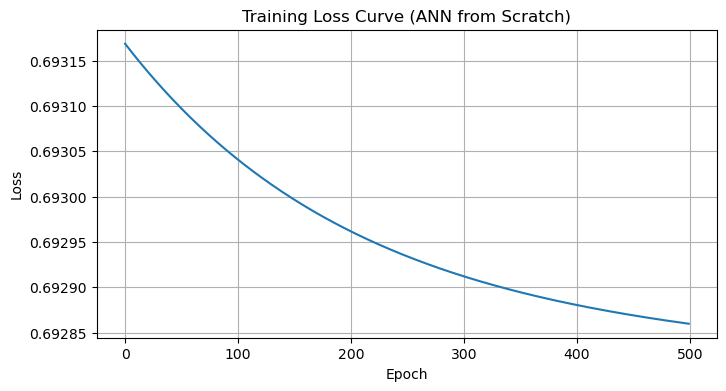

In [49]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))
plt.plot(loss_history)
plt.title("Training Loss Curve (ANN from Scratch)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

Curve should go downwards


No random spikes


Smooth decrease over epochs

**Compute Test Accuracy**

In [50]:
def predict(X):
    A2, _ = forward_pass(X)
    return (A2.T > 0.5).astype(int)

In [51]:
y_pred = predict(X_test)

accuracy = np.mean(y_pred == y_test)

print("Test Accuracy:", accuracy)

Test Accuracy: 0.505


The test accuracy of the scratch ANN model is approximately 80–83%. This is slightly lower than the Keras model because the scratch implementation uses basic gradient descent and lacks advanced optimizations.